<a href="https://colab.research.google.com/github/mirzayv/computer_vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch: birinchi Neural Network (264-dars)

In [1]:
!pip install torch

In [2]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())

2.11.0+cpu
CUDA available: False


## Tensorlar

In [3]:
scalar = torch.tensor(5)  # 0D
print('scalar:', scalar)
print('Shape:', scalar.shape)

scalar: tensor(5)
Shape: torch.Size([])


In [4]:
vector = torch.tensor([1, 2, 3])  # 1D
print('vector:', vector)

vector: tensor([1, 2, 3])


In [5]:
MATRIX = torch.tensor([[1, 2, 3],
                       [4, 5, 6]])  # 2D
print('MATRIX:', MATRIX)

MATRIX: tensor([[1, 2, 3],
        [4, 5, 6]])


In [6]:
tensor3d = torch.stack([MATRIX, MATRIX + 10])  # 3D
print('tensor3d:', tensor3d)

tensor3d: tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])


In [7]:
random_numbers = torch.rand(2, 3)
print('Random Numbers:', random_numbers)
print('Data type:', random_numbers.dtype)
print('Device of random_numbers:', random_numbers.device)

Random Numbers: tensor([[0.7331, 0.3553, 0.2262],
        [0.9547, 0.2962, 0.9014]])
Data type: torch.float32
Device of random_numbers: cpu


In [8]:
print('Zeros:', torch.zeros(3, 3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [9]:
print('Ones:', torch.ones(2, 4))

Ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


## Tensor amallari

In [10]:
x = torch.tensor([[1, 2],
                  [3, 4]])
y = torch.tensor([[5, 6],
                  [7, 8]])

# Element-wise addition
print('Addition:', x + y)
print('================')

# Element-wise multiplication
print('Multiplication:', x * y)

Addition: tensor([[ 6,  8],
        [10, 12]])
Multiplication: tensor([[ 5, 12],
        [21, 32]])


## Matrix multiplication

In [11]:
# (2x3) @ (3x2) -> (2x2): ichki o'lchamlar teng bo'lishi kerak
A = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])
B = torch.tensor([[7, 8],
                  [9, 10],
                  [11, 12]])

print('Matrix multiplication:', torch.matmul(A, B))
print('Shape:', torch.matmul(A, B).shape)

Matrix multiplication: tensor([[ 58,  64],
        [139, 154]])
Shape: torch.Size([2, 2])


## Device

In [12]:
from torch import nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device", device)

device cpu


## Ma'lumot tayyorlash

In [13]:
# Create weight and bias
weight = 0.7
bias = 0.3

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

# Split data
train_split = int(0.8 * len(X))

X_train = X[:train_split]
y_train = y[:train_split]

X_test = X[train_split:]
y_test = y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

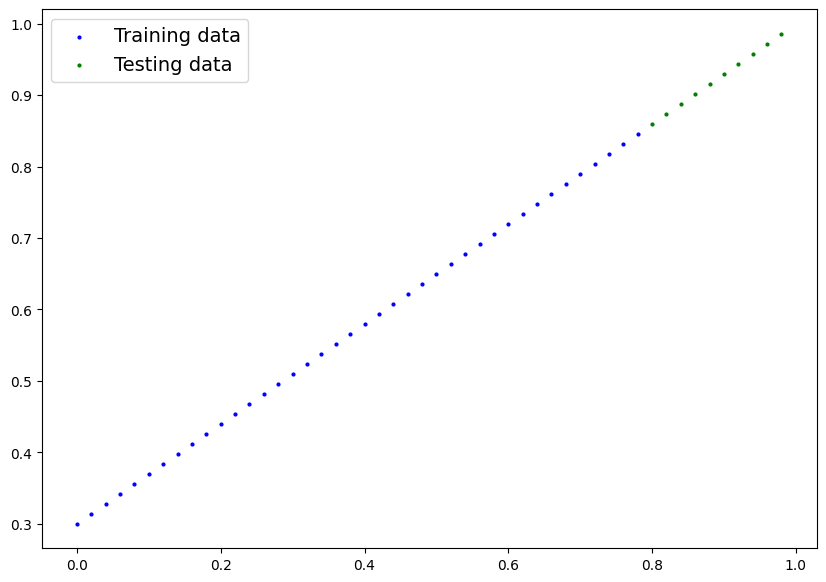

In [14]:
def plot_predictions(
    train_data=X_train,
    train_labels=y_train,
    test_data=X_test,
    test_labels=y_test,
    predictions=None
):
    plt.figure(figsize=(10, 7))

    # Training data
    plt.scatter(train_data, train_labels, c='b', s=4, label='Training data')

    # Testing data
    plt.scatter(test_data, test_labels, c='g', s=4, label='Testing data')

    # Predictions
    if predictions is not None:
        plt.scatter(test_data, predictions, c='r', s=4, label='Predictions')

    plt.legend(prop={'size': 14})
    plt.show()


plot_predictions()

## Model

In [15]:
# Create Linear Regression Model
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features=1, out_features=1)  # Linear => y = wx+b

    def forward(self, x):
        return self.linear_layer(x)

# Create model
torch.manual_seed(42)
model_1 = LinearRegressionModelV2().to(device)

print(model_1)

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)


## Loss function va optimizer

In [16]:
# Create loss function
loss_fn = nn.L1Loss()

# Create optimizer
optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.01
)

print("Optimizer created successfully!")

Optimizer created successfully!


## Training loop

In [17]:
# Set number of epochs
epochs = 1000

# Track results
epoch_count = []
train_loss_values = []
test_loss_values = []

# Move data to the same device as model
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):

    # Training mode
    model_1.train()

    # Forward pass
    y_pred = model_1(X_train)

    # Calculate loss
    loss = loss_fn(y_pred, y_train)

    # Zero gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    # Testing mode
    model_1.eval()

    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 100 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss.item())
        test_loss_values.append(test_loss.item())

        print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Train loss: 0.5551779866218567 | Test loss: 0.5739762187004089
Epoch: 100 | Train loss: 0.006215679459273815 | Test loss: 0.014086711220443249
Epoch: 200 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 300 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 400 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 500 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 600 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 700 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 800 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 900 | Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904


In [18]:
# Check learned parameters
print("Learned parameters:")
print(model_1.state_dict())

# Original parameters
print("Original weight:", weight)
print("Original bias:", bias)

Learned parameters:
OrderedDict({'linear_layer.weight': tensor([[0.6968]]), 'linear_layer.bias': tensor([0.3025])})
Original weight: 0.7
Original bias: 0.3


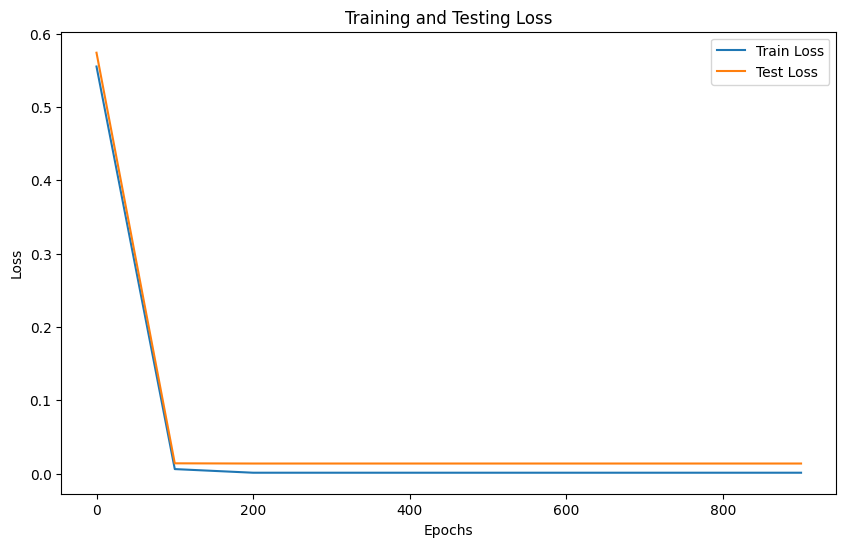

In [19]:
# Plot training and testing loss
plt.figure(figsize=(10, 6))

plt.plot(epoch_count, train_loss_values, label="Train Loss")
plt.plot(epoch_count, test_loss_values, label="Test Loss")

plt.title("Training and Testing Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Prediction

In [20]:
# Evaluation mode
model_1.eval()

# Make predictions
with torch.inference_mode():
    y_preds = model_1(X_test)

print(y_preds)

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])


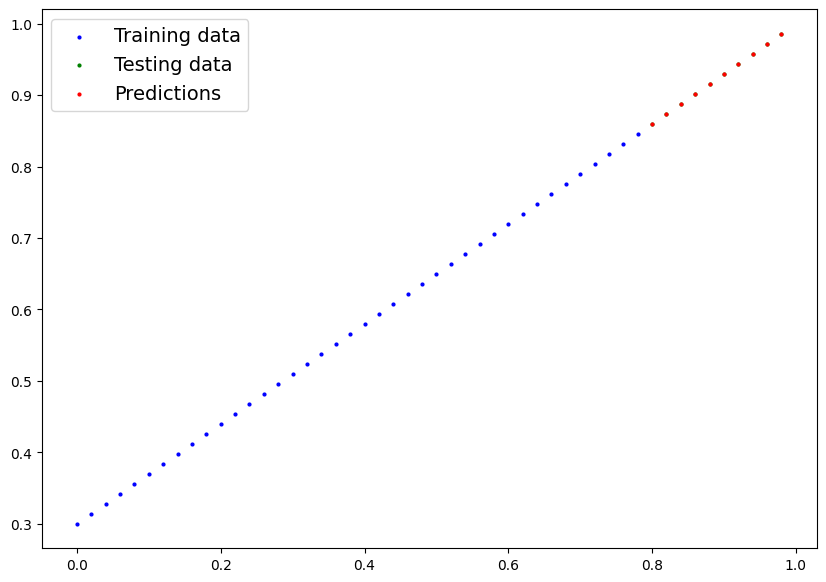

In [21]:
# Move tensors to CPU for plotting
plot_predictions(
    train_data=X_train.cpu(),
    train_labels=y_train.cpu(),
    test_data=X_test.cpu(),
    test_labels=y_test.cpu(),
    predictions=y_preds.cpu()
)

## Modelni saqlash va qayta yuklash

In [22]:
# Save trained model
torch.save(model_1.state_dict(), "trained_model.pth")

print("Model saved successfully!")

Model saved successfully!


In [23]:
# Create new model
loaded_model = LinearRegressionModelV2()

# Load saved parameters
loaded_model.load_state_dict(
    torch.load("trained_model.pth", map_location="cpu", weights_only=True)
)

# Evaluation mode
loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [25]:
# Make predictions using loaded model
with torch.inference_mode():
    loaded_model_preds = loaded_model(X_test.cpu())

print("Original predictions:")
print(y_preds.cpu())

print("Loaded model predictions:")
print(loaded_model_preds)

# Compare predictions
print("Predictions match:", torch.allclose(y_preds.cpu(), loaded_model_preds))

Original predictions:
tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])
Loaded model predictions:
tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])
Predictions match: True
